In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from sklearn.model_selection import train_test_split
import shap

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


/home/steak/Desktop/recursive-leverage-defi/analysis/whale-risk-supervised/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('whale_features_labeled.csv', parse_dates=['date'])
print(f'Shape: {df.shape}')
print(f'Whales: {df["whale_id"].unique()}')

Shape: (2506, 53)
Whales: <StringArray>
[ 'W-1', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17',
 'W-18', 'W-19',  'W-2', 'W-20', 'W-21', 'W-22', 'W-23',  'W-3',  'W-4',
  'W-5',  'W-6',  'W-7',  'W-8',  'W-9']
Length: 23, dtype: str


In [3]:
FEATURES = [
    'ltv',
    'ltv_lag_1',
    'ltv_lag_3',
    'ltv_lag_7',
    'ltv_vol_7d',
    'ltv_vol_14d',
    'distance_to_liq',
    'health_factor',
    'carry_spread',
    'carry_spread_levered',
    'leverage'
]

TARGET = 'risk_rebalance'

print(f'Features: {len(FEATURES)}')
print(f'Target: {TARGET}')
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())

Features: 11
Target: risk_rebalance

Target distribution:
risk_rebalance
0    2326
1     180
Name: count, dtype: int64


**We use 11 features:**

- `ltv`, `ltv_lag_1`, `ltv_lag_3`, `ltv_lag_7`: the current leverage ratio and its past values
- `ltv_vol_7d`, `ltv_vol_14d`: how much the leverage has been moving around recently
- `distance_to_liq`: how far the position is from being liquidated
- `health_factor`: the overall risk score from the protocol
- `carry_spread`, `carry_spread_levered`: the yield earned minus the cost of borrowing
- `leverage`: the position's leverage, `1 / (1 - ltv)`, so 0.90 LTV is 10x

**The target is `risk_rebalance`, not any position activity.**

A day with a supply, withdraw, borrow or repay only means the whale touched the position, which covers moving capital as much as managing risk. `risk_rebalance` counts the days on which leverage actually moved, so the model is asked to predict risk management rather than contact. This is a harder and rarer target: 7.2% of whale-days against 14.8% under the old broad flag.

**We left out the derived cadence and delta features to avoid data leakage:**

`risk_rebal_freq_7d`, `risk_rebal_freq_30d`, `days_since_risk_rebalance`, `delta_leverage_rel` and `delta_equity_rel` are all built directly from the target, so using them would let the model peek at the answer.

In [4]:
data = df.dropna(subset=FEATURES)

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape} Risk-rebalance rate: {y_train.mean():.1%}')
print(f'Test: {X_test.shape}  Risk-rebalance rate: {y_test.mean():.1%}')

Train: (1032, 11) Risk-rebalance rate: 5.7%
Test: (443, 11)  Risk-rebalance rate: 5.9%


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print('=== Logistic Regression (Baseline) ===')
print(classification_report(y_test, y_pred_lr))
print(f'ROC-AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]):.3f}')

=== Logistic Regression (Baseline) ===
              precision    recall  f1-score   support

           0       0.98      0.95      0.96       417
           1       0.42      0.62      0.50        26

    accuracy                           0.93       443
   macro avg       0.70      0.78      0.73       443
weighted avg       0.94      0.93      0.93       443

ROC-AUC: 0.881


**Logistic Regression Baseline Results**

We run Logistic Regression first as a simple baseline before XGBoost.

**Reading the results:**

Accuracy is 93%, but that number means little here: only 5.9% of test days risk-rebalance, so predicting zero every time would already score 94%. What matters is how well the model finds those days.

Recall is 0.62, so the model catches 62% of the actual risk rebalances and misses the other 38%.

Precision is 0.42, so when it predicts a risk rebalance it is right 42% of the time.

ROC-AUC is 0.881, a fairly good general ability to separate risk rebalances from quiet days.

The target is rarer than the old broad activity flag, which makes this a harder problem, yet the baseline separates the classes better than the old setup did. Predicting whether a whale will manage its risk is more learnable than predicting whether it will touch the position for any reason at all.

In [6]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=2,  # shallower trees
    learning_rate=0.05,  # slower learning
    subsample=0.8,  # use 80% of rows per tree
    colsample_bytree=0.8,  # use 80% of features per tree
    min_child_weight=5,  # need at least 5 samples per leaf
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print('=== XGBoost ===')
print(classification_report(y_test, y_pred_xgb))
print(f'ROC-AUC: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]):.3f}')

scale_pos_weight: 16.49


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.99      0.85      0.92       417
           1       0.26      0.81      0.39        26

    accuracy                           0.85       443
   macro avg       0.62      0.83      0.65       443
weighted avg       0.94      0.85      0.88       443



ROC-AUC: 0.901


**XGBoost Model and Results**

The scale_pos_weight of 16.49 tells XGBoost that quiet days outnumber risk rebalances by about 16 to 1. This stops the model from being lazy and just predicting 0 every time.

**Key settings explained simply:**

n_estimators is 50, so the model builds 50 decision trees.
max_depth is 2, so each tree is shallow. This stops the model from memorizing the training data.
learning_rate is 0.05, so the model learns slowly and carefully.
subsample is 0.8, so each tree only sees 80% of the rows. This adds variety between trees.
colsample_bytree is 0.8, so each tree only uses 80% of the features. This helps reduce overfitting.
min_child_weight is 5, so a group needs at least 5 samples before it can be split further. This stops the model from making tiny, meaningless splits.

---

**Results compared to the baseline:**

| Metric | Logistic Regression | XGBoost |
|---|---|---|
| Recall (risk rebalance) | 0.62 | 0.81 |
| Precision (risk rebalance) | 0.42 | 0.26 |
| ROC-AUC | 0.881 | 0.901 |

XGBoost is not better on every measure. It catches far more risk rebalances (recall of 0.81 versus 0.62) and ranks days better overall (ROC-AUC of 0.901 versus 0.881), but it pays for that recall with precision, dropping from 0.42 to 0.26.

Which model to prefer depends on the cost of being wrong. If the point is to flag positions that may be about to be risk-rebalanced, missing an event is worse than raising an alert, and XGBoost's recall is worth the extra false alarms. If alerts are expensive, the baseline is the better-calibrated choice.

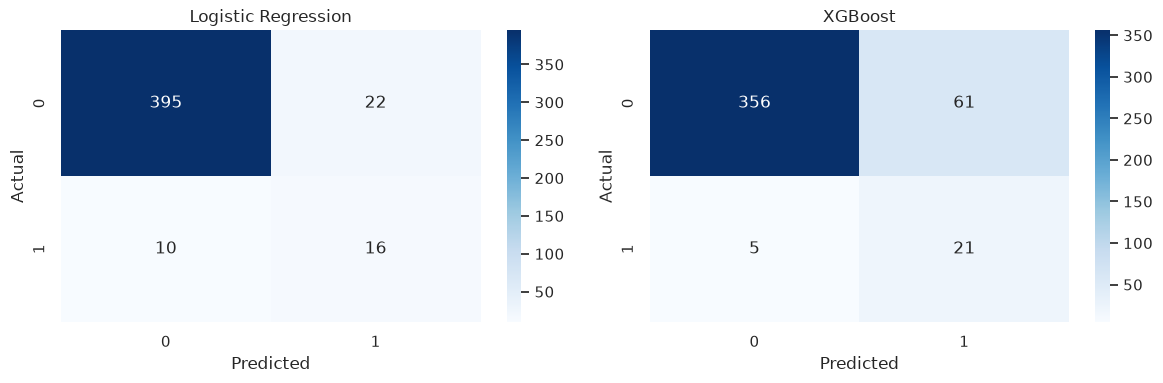

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, preds, title in zip(axes,
                            [y_pred_lr, y_pred_xgb],
                            ['Logistic Regression', 'XGBoost']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Confusion Matrix, Leverage Change Model**

Each matrix shows 4 numbers. Reading them:

Top left: correctly predicted no risk rebalance (true negatives)
Top right: predicted a risk rebalance but was wrong (false alarms)
Bottom left: missed actual risk rebalances (missed events)
Bottom right: correctly predicted a risk rebalance (true positives)

---

**Logistic Regression:**

Correctly caught 16 out of 26 risk rebalances.
Missed 10 of them.
Made 22 false alarms.

**XGBoost:**

Correctly caught 21 out of 26 risk rebalances.
Missed 5 of them.
Made 61 false alarms.

---

**What this means:**

XGBoost catches five more risk rebalances than Logistic Regression (21 versus 16) at the cost of 39 extra false alarms. That is a real trade, not a free win. Halving the misses is valuable when the point is to spot positions about to be risk-rebalanced, but the alert list nearly triples in length. With only 26 positive days in the test set, both models are working with thin evidence and the gap between them should not be over-read.

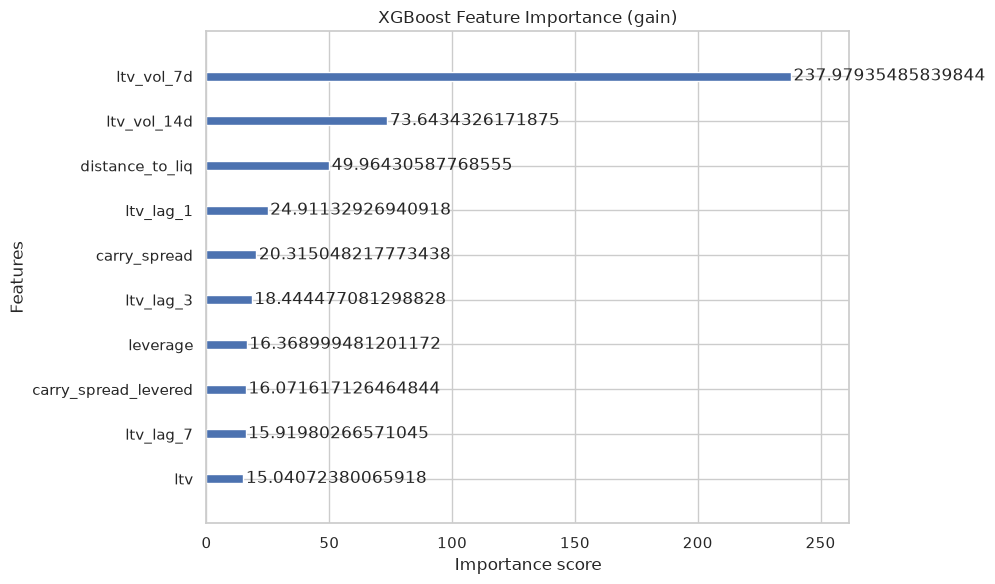

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
xgb.plot_importance(xgb_model, ax=ax, max_num_features=14, importance_type='gain')
ax.set_title('XGBoost Feature Importance (gain)')
plt.tight_layout()
plt.show()

This chart shows which features the model relied on most to predict a risk rebalance. A higher score means the feature was used in more splits.

Note that only 10 of the 11 features show up here. `health_factor` was never used by any tree, so XGBoost does not give it a score.

**Top features:**

`ltv_vol_7d` (52) dominates, as it did under the old target. How much the leverage ratio has moved over the past week is by far the strongest predictor that the whale is about to move it deliberately.

`carry_spread_levered` (18) and `carry_spread` (14) now sit near the top, which is a change from the broad activity target. Once capital moves and dust are removed, the economics of the position matter: a whale risk-rebalances when the levered carry makes it worth doing, not merely when it happens to be transacting.

`ltv_vol_14d` (17) and `ltv_lag_1` (13) follow, extending the same volatility and recent-history signal.

**Lower importance features:**

`ltv_lag_7` (7), `ltv_lag_3` (5), `distance_to_liq` (3), `leverage` (2) and `ltv` (1) are used sparingly. The level of leverage says much less than its recent movement.

**Key finding:**

Risk rebalances are driven by recent volatility in the leverage ratio and by the carry the position is earning, rather than by its level on any one day. That the carry features rise in importance under this target is the clearest sign that the split was worth making: the old flag mixed in capital movements that carry economics do not explain.

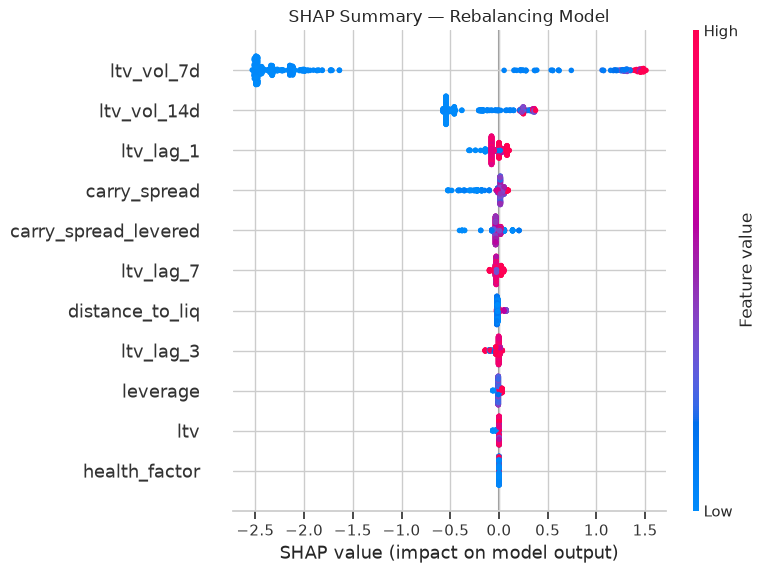

In [9]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=False)
plt.title('SHAP Summary — Rebalancing Model')
plt.tight_layout()
plt.show()

SHAP Summary, Leverage Change Model

Each dot is one day in the test set. The position on the x-axis shows how much that feature pushed the prediction toward a risk rebalance (right side) or away from it (left side). The color shows the feature value: pink means high, blue means low.

`ltv_vol_7d` dominates to an extent it did not under the old target, with a mean absolute contribution of 2.08 against 0.42 for the next feature and a range from -2.53 to +1.51. The effect is strongly one-sided: the two least volatile thirds of days both average about -2.4, pushing hard away from a risk rebalance, while the most volatile third averages -0.06. Stable leverage is close to proof that nothing will happen; volatile leverage merely removes that objection rather than predicting a change on its own.

`ltv_vol_14d` repeats the pattern at a fifth of the magnitude, so the recent window carries most of the signal.

`ltv_lag_1`, `carry_spread` and `carry_spread_levered` form a second tier around 0.04 to 0.06 mean absolute contribution. Their reach is asymmetric: `carry_spread` can push a day as far as -0.53 when the carry is poor, so a position that is not earning is one the whale leaves alone.

`ltv_lag_7`, `distance_to_liq`, `ltv_lag_3`, `leverage` and `ltv` contribute almost nothing, and `health_factor` is flat at exactly zero because no tree split on it. Both risk measures are derived from `ltv`, so whatever they carry is already available through the leverage features.

Overall the model is driven by how much the leverage ratio has been moving recently, with carry economics as a secondary influence. The level of leverage on any single day tells it very little.

In [10]:
results = df.loc[X_test.index].copy()
results['pred_risk_rebalance'] = y_pred_xgb
results['pred_proba_risk_rebalance'] = xgb_model.predict_proba(X_test)[:, 1]
results[['whale_id', 'date', 'risk_rebalance', 'pred_risk_rebalance', 'pred_proba_risk_rebalance']].to_csv(
    'predictions_risk_rebalance.csv', index=False)
print('Saved: predictions_risk_rebalance.csv')

Saved: predictions_risk_rebalance.csv
